# 08 — Explainability and business insights

## Goal of this step

Explain the frozen model globally and for one high-risk training customer. Turn the top five business fields into hypotheses that the business can test.

## Why this matters

SHAP is like splitting credit among teammates: it measures each feature's contribution relative to a background. Correlated teammates can share credit in different ways, so attribution explains this model rather than proving what causes churn.

Find the project root and import display tools. Reusable logic lives in src.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np  # noqa: F401
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
plt.rcParams["figure.figsize"] = (8, 4)


Use a seed-42 sample of 200 training customers and a 100-row training background. SHAP receives the same encoded matrix used by the estimator, preserving the saved preprocessing.

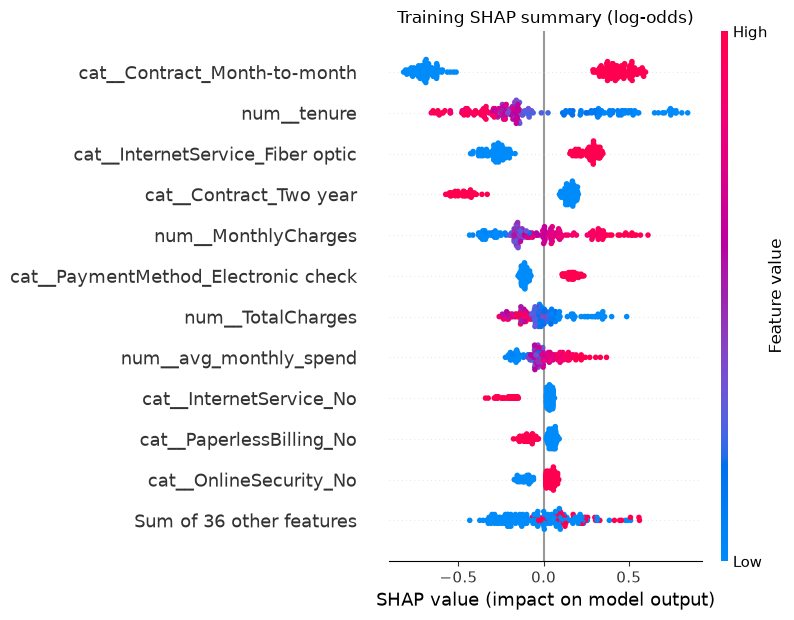

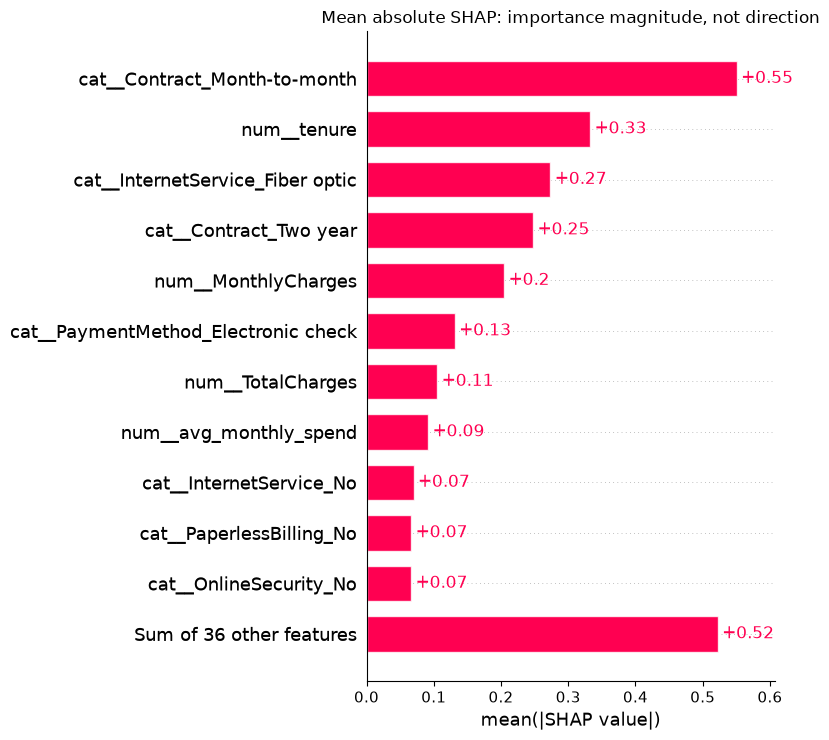

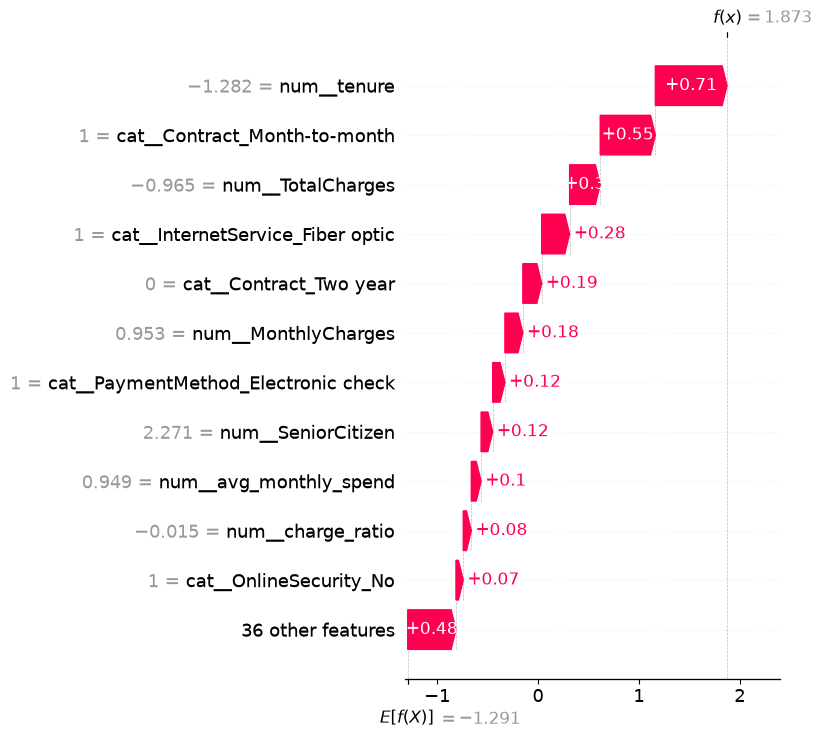

model_hash                      ec5c1872899ff5ec701bfb13da69655c339047b89c30ea...
training_sample_size                                                          200
background_size                                                               100
output_units                                                             log-odds
max_additivity_error                                                     0.000002
local_sample_position                                                          24
local_training_row_index                                                     1971
local_churn_probability                                                  0.866844
local_baseline_output                                                   -1.291354
local_final_output                                                       1.873341
global_importance_definition    Sum mean absolute SHAP over encoded columns pe...
caveat                          Training-only sample; correlated features shar...
dtype: object

In [2]:
from src.explain import run_explanations
from src.config import REPORTS
drivers, info = run_explanations(show=True)
display(pd.Series(info))

**Interpretation:** The beeswarm shows signed effects and value patterns; the bar shows average magnitude; the waterfall starts at the background output and adds feature contributions for the highest-risk customer in this sample.

Inspect global drivers grouped back to business fields. For one-hot columns we sum their mean absolute SHAP magnitudes; global magnitude does not tell us whether a field increases risk.

In [3]:
display(drivers.head(10))
display(pd.read_csv(REPORTS / 'local_explanation.csv').head(10))

,feature,mean_abs_shap,recommendation
0,Contract,0.818452,"Offer clear, optional longer-term plan choices..."
1,InternetService,0.356114,Investigate service experience and reliability...
2,tenure,0.332707,Pilot stronger onboarding and early check-ins;...
3,MonthlyCharges,0.204806,Review bill clarity and plan value with custom...
4,PaymentMethod,0.141016,"Offer convenient, optional payment reminders o..."
5,TotalCharges,0.105339,Review bill clarity and plan value with custom...
6,PaperlessBilling,0.095279,"Offer convenient, optional payment reminders o..."
7,avg_monthly_spend,0.091745,Review bill clarity and plan value with custom...
8,OnlineSecurity,0.084173,Pilot clearer support and bundle-value communi...
9,MultipleLines,0.063239,Investigate service experience and reliability...


,encoded_feature,transformed_value,shap_contribution,absolute_contribution
0,num__tenure,-1.282119,0.710178,0.710178
1,cat__Contract_Month-to-month,1.000000,0.546327,0.546327
2,num__TotalCharges,-0.965436,0.303345,0.303345
3,cat__InternetService_Fiber optic,1.000000,0.276910,0.276910
4,cat__Contract_Two year,0.000000,0.186868,0.186868
5,num__MonthlyCharges,0.953476,0.177739,0.177739
6,cat__PaymentMethod_Electronic check,1.000000,0.121016,0.121016
7,num__SeniorCitizen,2.271100,0.115109,0.115109
8,num__avg_monthly_spend,0.948505,0.096919,0.096919
9,num__charge_ratio,-0.015463,0.079869,0.079869


**Interpretation:** Positive local contributions increase the model output for this customer, and negative ones lower it. Numeric values in the local table are standardized; they are not raw bills or tenure.

Translate the five largest business-field attributions into practical, testable actions. Log-odds contributions add before conversion to probability; tree probability explanations, when applicable, use probability units.

In [4]:
display(drivers.head(5)[['feature', 'recommendation']])
display(pd.Series({'customer_row': info['local_training_row_index'], 'predicted_churn_probability': info['local_churn_probability'], 'SHAP_units': info['output_units'], 'max_reconstruction_error': info['max_additivity_error']}))

,feature,recommendation
0,Contract,"Offer clear, optional longer-term plan choices..."
1,InternetService,Investigate service experience and reliability...
2,tenure,Pilot stronger onboarding and early check-ins;...
3,MonthlyCharges,Review bill clarity and plan value with custom...
4,PaymentMethod,"Offer convenient, optional payment reminders o..."


customer_row                       1971
predicted_churn_probability    0.866844
SHAP_units                     log-odds
max_reconstruction_error       0.000002
dtype: object

**Interpretation:** The high-risk explanation reconstructs the frozen model output. Recommendations are experiment proposals; SHAP alone does not show that changing a field prevents churn.

## Common mistakes

- Labeling log-odds contributions as probability percentage points.
- Using held-out labels to decide which customer story looks persuasive.
- Treating SHAP rankings as a causal retention playbook.

## Key takeaways

- Global plots explain patterns across a training sample.
- The local explanation is checked for additive consistency.
- Business actions require validation beyond predictive associations.

## Next step

09_summary.ipynb: use predict_one and review results, limitations, and reproducibility.